In [1]:
!rm -rf ~/.cache/matplotlib
!fc-cache -f -v

Font directories:
	/home/mariia/.local/share/fonts
	/home/mariia/snap/code/268/.local/share/fonts
	/home/mariia/snap/code/268/fonts
	/snap/code/268/usr/share/fonts
	/usr/share/ubuntu/fonts
	/usr/share/gnome/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/var/lib/snapd/desktop/fonts
	/home/mariia/.fonts
	/usr/share/fonts/X11
	/usr/share/fonts/cMap
	/usr/share/fonts/cmap
	/usr/share/fonts/opentype
	/usr/share/fonts/truetype
	/usr/share/fonts/type1
	/usr/share/fonts/X11/Type1
	/usr/share/fonts/X11/encodings
	/usr/share/fonts/X11/misc
	/usr/share/fonts/X11/util
	/usr/share/fonts/cmap/adobe-cns1
	/usr/share/fonts/cmap/adobe-gb1
	/usr/share/fonts/cmap/adobe-japan1
	/usr/share/fonts/cmap/adobe-japan2
	/usr/share/fonts/cmap/adobe-korea1
	/usr/share/fonts/opentype/malayalam
	/usr/share/fonts/opentype/noto
	/usr/share/fonts/opentype/urw-base35
	/usr/share/fonts/truetype/Gargi
	/usr/share/fonts/truetype/Gubbi
	/usr/share/fonts/truetype/Nakula
	/usr/share/fonts/truetype/Navilu
	/usr/share/fonts/

In [2]:
import pandas as pd
from upsetplot import from_indicators, UpSet
import matplotlib.pyplot as plt
from itertools import combinations

In [36]:
df = pd.read_csv('../data/meta/meta_with_detection.csv')
df.columns

Index(['orf_id', 'ORF_ranges', 'Protein', 'gene_id', 'gene_biotype',
       'gene_name', 'transcript_id', 'uniprot_gn_ids', 'cl_mean', 'ps_mean',
       'ps_n_translated', 'ps_translated', 'translated_A673',
       'translated_SKNMC', 'translated_MHHES1', 'translated_RDES',
       'translated_TC106', 'EwS_specific', 'orf_category_new',
       'same_as_orfquant', 'same_as_orfquant_start', 'neotranscript_orf_type',
       'neotranscript_type', 'isoform_final', 'distance_chip', 'distance_msat',
       'peak_orth_near', 'ggaa_near', 'Peptides_SB', 'Number_SB',
       'Peptides_WB', 'Number_WB', 'class', 'any_peptide_found_in_IP',
       'result_A673', 'result_SKNMC', 'result_MHHES', 'result_TC106',
       'result_RDES', 'detected_ip_fp', 'detected_ip_casanovo', 'detected_MSK',
       'detected_tr', 'detected_DKFZ', 'orf_cathegoty_toplot', 'detected_1',
       'detected_1_in_at_least_2_samples', 'detected_2',
       'detected_2_in_at_least_2_samples', 'detected_3',
       'detected_3_in_at_

In [37]:
df['orf_cathegoty_toplot'] = df['neotranscript_orf_type'].where(df['neotranscript_orf_type'] != 'Non-canonical ORF general', df['orf_category_new'])
df = df[df['orf_cathegoty_toplot']!='ORF_variant']

In [38]:
df['detected_ip'] = df['detected_ip_casanovo']|df['detected_ip_fp']

In [39]:
dfx = df[['orf_id', 'detected_ip', 'detected_MSK',  'detected_tr','detected_DKFZ' ]]

In [40]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42        # ← renders text as text in Illustrator (Type 1 → TrueType)
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'Arial'    # ← Arial font


detected_ip  detected_MSK  detected_tr  detected_DKFZ
True         False         False        False            765
False        True          False        False            121
             False         True         False             40
                           False        True              34
True         True          False        False              6
             False         True         False              4
                           False        True               5
False        True          True         False             25
                           False        True              14
             False         True         True               8
True         True          True         False              2
                           False        True               3
             False         True         True               3
False        True          True         True               7
True         True          True         True               2
dtype: int64


/home/mariia/miniforge3/envs/analysis/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/mariia/miniforge3/envs/analysis/lib/python3.12/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are 

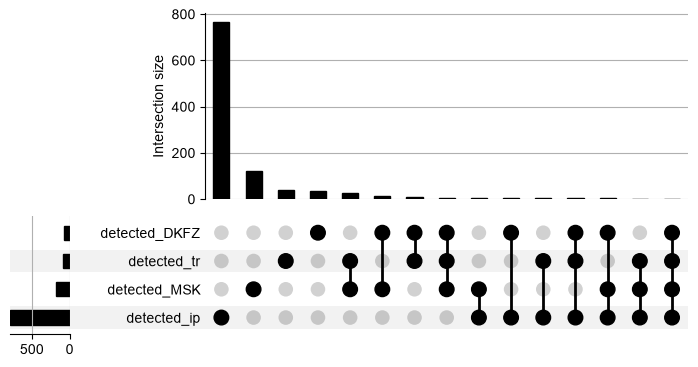

In [41]:
set_cols = ['detected_ip', 'detected_MSK',  'detected_tr','detected_DKFZ']
bool_df = dfx[set_cols].astype(bool)

# For inclusive intersections: for each possible combo of sets,
# count elements that are in ALL sets of that combo (regardless of other memberships)
index_tuples = []
counts = []

for r in range(1, len(set_cols) + 1):
    for combo in combinations(set_cols, r):
        # element must be True in every set in this combo
        mask = bool_df[list(combo)].all(axis=1)
        count = mask.sum()
        # MultiIndex tuple: True only for sets IN this combo
        index_tuples.append(tuple(col in combo for col in set_cols))
        counts.append(count)

index = pd.MultiIndex.from_tuples(index_tuples, names=set_cols)
data = pd.Series(counts, index=index)

print(data)  # sanity check before plotting

fig = plt.figure(figsize=(10, 5))

upset = UpSet(
    data,
    subset_size='sum',
    sort_by='cardinality',
    show_counts=False,
    facecolor='black',
    element_size=30
)

upset.plot(fig)

fig.savefig(
    'upset_plot.pdf',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [42]:
hlala = pd.read_csv("count_peptides/HLA_la_reported_cryptic_peptides_with_metadata.csv")
hlala['coordinates'] = hlala['Location']
hlala['coordinates'] = hlala['coordinates'].apply(lambda x: x.replace('-:', ':').replace('+:', ':'))
hlala['coordinates'] = hlala['coordinates'].apply(lambda x: x.replace('|', '|'+x[:x.index(':')]+':') if '|' in x else x)
hlala['coordinates'] = hlala['coordinates'].apply(lambda x: x.split('|') if '|' in x else [x])
hlala = hlala.explode('coordinates')
merge = df.merge(hlala, left_on='ORF_ranges', right_on='coordinates')
merge

,orf_id,ORF_ranges,Protein,gene_id,gene_biotype,gene_name,transcript_id,uniprot_gn_ids,cl_mean,ps_mean,...,Sequence.nr,number.patients.shared,patients,best.Q,tissue,best HLA binder,best.peptide,best.ALC,modified,coordinates


In [44]:
df = df[df[set_cols].any(axis=1)]
len(df)

911

In [45]:
df['detected_in_hla_la'] = False
df['hla_la_peptide'] = None
for index, row in hlala.iterrows():
    for index2, row2 in df.iterrows():
        if row['Sequence'] in row2['Protein']:
            df.at[index2, 'detected_in_hla_la'] = True
            df.at[index2, 'hla_la_peptide'] = row['Sequence']
            print(f"Match found: {row['Sequence']} in {row2['orf_id']}: {row2['Protein']}")

/tmp/ipykernel_2411301/3855357570.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['detected_in_hla_la'] = False
/tmp/ipykernel_2411301/3855357570.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['hla_la_peptide'] = None


Match found: AAATAVAMR in ENST00000428135_12_167: MAARPSRATGPRGGQRSRVKPPPGRRLKEQLPPLAAARAVFAAATAVAMRRG
Match found: VAAEVAGAGR in ENST00000393972_103_192: MGRAGTMAVAAEVAGAGRLAVEEAVVLRGL
Match found: MAASGAGAEVSGR in ENSG00000143570_ENSG00000143545__ENST00000471173__ncRNA__6__ATG: MAASGAGAEVSGR
Match found: ETSQLSQIGR in ENSG00000168575_ENSG00000254165__ENST00000518384__uORF__8__ATG: MCQMPEETSQLSQIGRKNMECVLPLTEHNQMNCPDSSLQTSS
Match found: ETSQLSQIGR in ENST00000517366_1_168: MMQISVFLPAAWLQLILAGEETSQLSQIGRKNMECVLPLTEHNQMNCPDSSLQTSS
Match found: DSAPSAQALTR in ENSG00000204956_ENSG00000240184__ENST00000308177__uORF__25__ATG: MSDSAPSAQALTR
Match found: ETVASAATVGAAR in ENST00000282570_80_136: METVASAATVGAAREKVAV
Match found: AAAAFVVPR in ENSG00000102531__ENST00000492622__uORF__3__ATG: MAAAAFVVPRVKQKAGATRRGSEERG
Match found: IWDLSITRL in TCONS_00673441_793_924: MPLLRPVSSHEPQHKTDGPVLTVDNFPCLSKRWDSIWDLSITRL
Match found: ASAAVRVAY in TCONS_00635532_60_152: MLTAPGDRRAGEPCSVAPRSASAAVRVAYRS
Match 

In [46]:
df['detected_in_hla_la'].value_counts()

detected_in_hla_la
False    762
True     149
Name: count, dtype: int64

In [47]:
df[df['detected_in_hla_la']]['orf_category_new'].value_counts()

orf_category_new
uORF              79
uoORF             32
intORF            18
lncRNA ORF        15
pseudogene ORF     3
doORF              1
dORF               1
Name: count, dtype: int64

In [48]:
cols = [
    'result_A673', 'result_SKNMC', 'result_MHHES',
    'result_TC106', 'result_RDES'
]

df['n_downregulated'] = df[cols].eq('downregulated').sum(axis=1).astype(int)
df['n_downregulated'].value_counts()

/tmp/ipykernel_2411301/2927263675.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['n_downregulated'] = df[cols].eq('downregulated').sum(axis=1).astype(int)


n_downregulated
0    647
1    157
2     66
3     21
4     18
5      2
Name: count, dtype: int64

In [50]:
df[df['n_downregulated'] >= 3]['detected_in_hla_la'].value_counts()

detected_in_hla_la
False    39
True      2
Name: count, dtype: int64

In [52]:
df[df['n_downregulated'] >= 3]['detected_ip'].value_counts()

detected_ip
True     28
False    13
Name: count, dtype: int64

In [53]:
df['type_of_fusion_regulation'] = df['n_downregulated'].apply(lambda x: 'EF1 controlled' if x >= 3 else 'Not EF1 controlled')
df['type'] = df['neotranscript_orf_type'].where((df['neotranscript_orf_type'] == 'Neogene ORF')|(df['neotranscript_orf_type'] == 'Out-of-frame ORF')|(df['neotranscript_orf_type'] == 'In-frame ORF'), df['type_of_fusion_regulation'])
df['type'].value_counts()

/tmp/ipykernel_2411301/662108000.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['type_of_fusion_regulation'] = df['n_downregulated'].apply(lambda x: 'EF1 controlled' if x >= 3 else 'Not EF1 controlled')
/tmp/ipykernel_2411301/662108000.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['type'] = df['neotranscript_orf_type'].where((df['neotranscript_orf_type'] == 'Neogene ORF')|(df['neotranscript_orf_type'] == 'Out-of-frame ORF')|(df['neotranscript_orf_type'] == 'In-frame ORF'), df['type_of_fusio

type
Not EF1 controlled    849
EF1 controlled         33
In-frame ORF           15
Neogene ORF            13
Out-of-frame ORF        1
Name: count, dtype: int64

In [25]:
palette = {
    "Neogene ORF": "#1b365d",
    "In-frame ORF": "#6ea9d2",
    "Out-of-frame ORF": "#D0E8F8",
    "Not EF1 controlled": "#F0F0F0",
    "EF1 controlled": "#B1D855"
}

/home/mariia/miniforge3/envs/analysis/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/mariia/miniforge3/envs/analysis/lib/python3.12/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are 

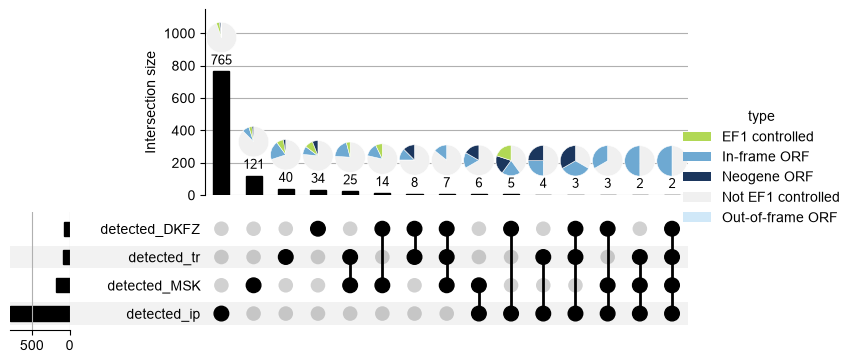

In [55]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from upsetplot import UpSet

# Use your existing palette dictionary:
# palette = {'type_A': '#4477AA', 'type_B': '#EE6677', ...}

type_series = df['type'].fillna('Missing').astype(str)

# Ensure every type has a color in palette
type_categories = sorted(type_series.unique())
missing_types = set(type_categories) - set(palette)

if missing_types:
    raise ValueError(f"Missing colors in palette for: {missing_types}")

# Create UpSet plot
fig = plt.figure(figsize=(12, 6))

upset = UpSet(
    data,
    subset_size='sum',
    sort_by='cardinality',
    show_counts=False,
    facecolor='black',
    element_size=30
)

axes = upset.plot(fig)
bar_ax = axes['intersections']

# Add numerical labels above the bars
bar_ax.bar_label(
    bar_ax.containers[0],
    fmt='%d',
    padding=3,
    fontsize=9
)

# Reserve space above the bars for pie charts and labels
bar_heights = [bar.get_height() for bar in bar_ax.patches]
max_height = max(bar_heights) if bar_heights else 1
bar_ax.set_ylim(0, max_height * 1.5)

# Add pie charts above the corresponding bars
plotted_intersections = upset.intersections.index
pie_size = 0.38  # inches

for bar, intersection in zip(bar_ax.patches, plotted_intersections):

    combo = [
        col for col, included in zip(set_cols, intersection)
        if included
    ]

    if not combo:
        continue

    # Inclusive intersection: rows must belong to all sets in combo
    mask = bool_df[combo].all(axis=1)

    type_counts = type_series.loc[mask].value_counts()
    type_counts = type_counts[type_counts > 0]

    if type_counts.empty:
        continue

    # Position pie above its bar
    x_center = bar.get_x() + bar.get_width() / 2
    y_top = bar.get_height() + max_height * 0.12

    x_display, y_display = bar_ax.transData.transform(
        (x_center, y_top)
    )
    x_fig, y_fig = fig.transFigure.inverted().transform(
        (x_display, y_display)
    )

    pie_ax = fig.add_axes([
        x_fig - pie_size / (2 * fig.get_figwidth()),
        y_fig,
        pie_size / fig.get_figwidth(),
        pie_size / fig.get_figheight()
    ])

    pie_ax.pie(
        type_counts.values,
        colors=[palette[t] for t in type_counts.index],
        startangle=90,
        counterclock=False,
        wedgeprops={'linewidth': 0.4, 'edgecolor': 'white'}
    )

    pie_ax.set_aspect('equal')
    pie_ax.set_axis_off()

# Legend for type categories
legend_handles = [
    Patch(facecolor=palette[t], label=t)
    for t in type_categories
]

fig.legend(
    handles=legend_handles,
    title='type',
    loc='center left',
    bbox_to_anchor=(0.88, 0.5),
    frameon=False
)

fig.savefig(
    'upset_plot_with_type_pies.pdf',
    dpi=300,
    bbox_inches='tight'
)

plt.show()